# Intensity comparison — whole-region features, separated by positive group

Compare **cone_only**, **sign_only**, and **both** separately. Every histogram/statistic is computed over the **entire annotation box or entire comparison patch**. There is no internal sliding neighborhood and no local heatmap.

Each feature gets its own cell within each group. Static example plots explain the feature; the summary uses all eligible positive validation images. Original annotations are uncorrected predictions. Unannotated patches may contain missed targets, so this is exploratory target-vs-unannotated discrimination, **not final detector accuracy**. `both` contains individual cone/sign boxes, not a combined enclosing box.

Dependencies: numpy, pandas, pillow, matplotlib, ipywidgets. Run all cells in order. Test is never read.


### Display-only context enlargement

Images remain **grayscale**. Example panels show a surrounding crop approximately twice the box width and height (clipped at image boundaries), with a colored outline identifying the exact computation region. This changes only the display, not the pixels used for any feature or evaluation. Enlarging a low-resolution crop cannot recover missing detail.


## Setup

For Colab, run `from google.colab import drive; drive.mount('/content/drive')` first. The known Drive project path is included below. Local Jupyter can locate the project automatically.


In [1]:
from pathlib import Path
from functools import lru_cache
import csv
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display

# Colab: mount Drive first; adjust this path if your copy is elsewhere.
COLAB_PROJECT = Path('/content/drive/MyDrive/ComputerVision/Midterm/midterm-csc74030-main')
if COLAB_PROJECT.is_dir():
    PROJECT = COLAB_PROJECT
else:
    PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / 'Test Dataset' / 'validation' / 'images.csv').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Mount Drive and set COLAB_PROJECT to your project folder.')
DATA = PROJECT / 'Test Dataset' / 'validation'
images = pd.read_csv(DATA / 'images.csv', dtype={'id': str})
annotations = pd.read_csv(DATA / 'annotations.csv')
POSITIVE_GROUPS = ['cone_only', 'sign_only', 'both']
images = images[images.group.isin(POSITIVE_GROUPS)].copy()
image_meta = images.set_index('image').to_dict('index')
valid_rows, invalid_rows = [], []
for row_id, row in annotations.iterrows():
    if row.image not in image_meta:
        continue
    im = image_meta[row.image]
    if 0 <= row.x0 < row.x1 <= im['width'] and 0 <= row.y0 < row.y1 <= im['height']:
        valid_rows.append(dict(row, annotation_row=row_id))
    else:
        invalid_rows.append(dict(row, annotation_row=row_id))
objects = pd.DataFrame(valid_rows)
print(f'{len(images)} positive validation images; {len(objects)} valid boxes; {len(invalid_rows)} excluded boxes.')
display(images.groupby('group').size().rename('images').to_frame())

@lru_cache(maxsize=12)
def load_image(relative, blur=False):
    with Image.open(DATA / relative) as im:
        rgb = im.convert('RGB')
        # PIL L: 8-bit luminance approximation from RGB.
        gray = rgb.convert('L')
        if blur:
            gray = gray.filter(ImageFilter.GaussianBlur(radius=1))
        return np.array(rgb), np.array(gray)


96 positive validation images; 228 valid boxes; 1 excluded boxes.


,images
group,
both,16
cone_only,40
sign_only,40


## Shared formulas

Histogram p(r)=n(r)/N; mean = Σr p(r); population variance = Σ(r−mean)²p(r). Statistical features use exact 256 gray levels. Plot histograms use 32 equal-width bins. Trimmed mean removes 10% of samples from **each tail**; entropy uses log₂. RMS contrast is standard deviation here. Gray-range fraction uses the inclusive fixed range [64,192]. These are references, not tuned parameters. Histogram normalization does not remove illumination changes.


In [2]:
def intensity_histogram(pixels, bins=256):
    values = np.asarray(pixels)
    if values.size == 0:
        raise ValueError('The region contains no pixels.')
    if values.dtype != np.uint8:
        raise ValueError('Expected uint8 grayscale pixels.')
    counts, edges = np.histogram(values.ravel(), bins=bins, range=(0, 256))
    return counts / counts.sum(), edges


def intensity_statistics(pixels, trim=0.1, gray_range=(64, 192)):
    if not 0 <= trim < 0.5:
        raise ValueError('trim must be in [0, 0.5).')
    p, _ = intensity_histogram(pixels)
    levels = np.arange(256, dtype=float)
    mean = np.dot(levels, p)
    variance = np.dot((levels - mean)**2, p)
    values = np.sort(np.asarray(pixels).ravel())
    cut = int(np.floor(trim * values.size))
    kept = values[cut:values.size-cut] if cut else values
    lo, hi = gray_range
    if not 0 <= lo <= hi <= 255:
        raise ValueError('Expected 0 <= low <= high <= 255.')
    return {'Mean': mean, 'Variance': variance, 'Std / RMS contrast': np.sqrt(variance),
            'Median': float(np.median(values)), 'Mode': float(np.argmax(p)),
            'Trimmed mean': float(kept.mean()),
            'Entropy (bits)': float(-np.sum(p[p > 0] * np.log2(p[p > 0]))),
            'Gray-range fraction': float(p[lo:hi+1].sum())}

# Numeric checks against direct pixel computations (including even-size median).
sample = np.array([0, 0, 10, 20, 200, 255], dtype=np.uint8)
s = intensity_statistics(sample)
assert np.isclose(s['Mean'], sample.mean())
assert np.isclose(s['Variance'], sample.astype(float).var())
assert s['Median'] == np.median(sample)
assert np.isclose(intensity_histogram(sample)[0].sum(), 1)
assert intensity_statistics(np.full((3, 3), 42, dtype=np.uint8))['Variance'] == 0


## Select regions

A deterministic same-size patch outside **all supplied boxes** is paired with each annotation. Nearby patches are preferred. If none exists, the pair is excluded and reported. Background masks also conservatively exclude clipped positive-area source boxes that fail object-analysis validation. Repeated boxes/overlapping targets remain in the original annotations. Each image receives equal weight in the quantitative summary to reduce the effect of crowded scenes.


In [3]:
def xyxy(row):
    return tuple(int(v) for v in (np.floor(row.x0), np.floor(row.y0),
                                 np.ceil(row.x1), np.ceil(row.y1)))


def region_data(relative, object_index=0, blur=False):
    rgb, gray = load_image(relative, blur)
    rows = objects[objects.image == relative].reset_index(drop=True)
    row = rows.iloc[min(object_index, len(rows)-1)]
    box = xyxy(row)
    x0, y0, x1, y1 = box
    h, w = gray.shape
    excluded = np.zeros((h, w), dtype=bool)
    for _, other in annotations[annotations.image == relative].iterrows():
        a,b,c,d = xyxy(other)
        a,c = np.clip([a,c],0,w); b,d = np.clip([b,d],0,h)
        excluded[b:d,a:c] = True
    regions = {'Annotation': gray[y0:y1, x0:x1]}
    boxes = {'Annotation': box}
    pw, ph = x1-x0, y1-y0
    # Integral occupancy makes overlap checks constant-time.
    integral = np.pad(excluded.astype(np.int64), ((1,0),(1,0))).cumsum(0).cumsum(1)
    xs = sorted(set(range(0,w-pw+1,max(1,pw//2))) | {w-pw})
    ys = sorted(set(range(0,h-ph+1,max(1,ph//2))) | {h-ph})
    candidates = []
    for y in ys:
        for x in xs:
            occupied = integral[y+ph,x+pw]-integral[y,x+pw]-integral[y+ph,x]+integral[y,x]
            if occupied == 0:
                candidates.append(((x-x0)**2+(y-y0)**2,x,y))
    if candidates:
        _,x,y = min(candidates)
        regions['Unannotated patch'] = gray[y:y+ph,x:x+pw]
        boxes['Unannotated patch'] = (x,y,x+pw,y+ph)
    ring = np.zeros_like(excluded)
    ring[max(0,y0-ph):min(h,y1+ph),max(0,x0-pw):min(w,x1+pw)] = True
    ring &= ~excluded
    if ring.any(): regions['Surrounding ring'] = gray[ring]
    if (~excluded).any(): regions['All unannotated pixels'] = gray[~excluded]
    return rgb, gray, row, regions, boxes


def region_table(regions, trim=.1, gray_range=(64,192)):
    return pd.DataFrame({name: {'Pixels': pixels.size,
                        **intensity_statistics(pixels,trim,gray_range)}
                         for name,pixels in regions.items()}).T


In [4]:
FEATURES = ['Histogram', 'Mean', 'Variance', 'Std / RMS contrast', 'Median',
            'Mode', 'Trimmed mean', 'Entropy (bits)', 'Gray-range fraction']
BINS = 32

# Cache only small feature vectors and the first displayed pair per group.
pair_records = []
example_pairs = {}
missing_pairs = []
for group in POSITIVE_GROUPS:
    for relative in images[images.group == group].image:
        rows = objects[objects.image == relative]
        for index in range(len(rows)):
            rgb, gray, row, regions, boxes = region_data(relative, index)
            if 'Unannotated patch' not in regions:
                missing_pairs.append((group, relative, int(row.annotation_row)))
                continue
            a, b = regions['Annotation'], regions['Unannotated patch']
            record = dict(group=group, image=relative, annotation_row=int(row.annotation_row))
            for label, patch in [('target', a), ('background', b)]:
                stats = intensity_statistics(patch)
                record[label] = {'Histogram': intensity_histogram(patch, BINS)[0],
                                 **{k: np.array([v]) for k,v in stats.items()}}
            pair_records.append(record)
            if group not in example_pairs:
                example_pairs[group] = (relative, index)
    print(group, ':', sum(r['group']==group for r in pair_records), 'paired annotations')
print('Pairs excluded because no unannotated patch was found:', len(missing_pairs))

COMBINATIONS = {
    'Mean + Variance': ['Mean','Variance'],
    'Variance + Entropy': ['Variance','Entropy (bits)'],
    'Mean + Std + Entropy': ['Mean','Std / RMS contrast','Entropy (bits)'],
}
for record in pair_records:
    for label in ['target','background']:
        for name,components in COMBINATIONS.items():
            record[label][name]=np.concatenate([record[label][k] for k in components])


cone_only : 78 paired annotations


sign_only : 56 paired annotations


both : 94 paired annotations
Pairs excluded because no unannotated patch was found: 0


## Quantitative comparison: image-separated validation folds

Within each group, split images into four deterministic folds (seed 42). A held-out image's targets and comparison patches never enter its reference centroids. For each feature, compute target/background centroids from the other folds; classify by the closer centroid using L1 distance. Each training image contributes equally to each centroid. Exact distance ties score 0.5. No threshold is tuned.

Report the mean of per-image balanced accuracy. Since every target has a paired background, a constant prediction scores 50%. This is a simple common comparison rule, not proof that a feature is optimal under every matcher. Histogram uses 32 dimensions; scalar summaries use one. The evaluation is still on GT-sized crops, not Experiment A's detection-window bank. Similar scenes may span folds, and source-label errors affect results.


Three predeclared combinations are also evaluated: Mean+Variance, Variance+Entropy, Mean+Std+Entropy. Combination coordinates are divided by training-fold standard deviation before L1 matching; held-out images do not determine scaling. Combinations were added after inspecting the scalar results and are exploratory. Their apparent advantage needs confirmation on subsequent detection evaluation. Do not combine variance and standard deviation as separate coordinates: one is determined by the other.


In [5]:
def compare_features(records):
    results = []
    for group in POSITIVE_GROUPS:
        subset = [r for r in records if r['group']==group]
        names = np.array(sorted({r['image'] for r in subset}))
        rng = np.random.default_rng(42)
        rng.shuffle(names)
        folds = {name:i%4 for i,name in enumerate(names)}
        for feature in [*FEATURES,*COMBINATIONS]:
            per_image = {}
            for fold in range(4):
                train = [r for r in subset if folds[r['image']]!=fold]
                held = [r for r in subset if folds[r['image']]==fold]
                if not train or not held: continue
                train_names = sorted({r['image'] for r in train})
                centroids = {}
                for label in ['target','background']:
                    centroids[label] = np.mean([
                        np.mean([r[label][feature] for r in train if r['image']==name],axis=0)
                        for name in train_names],axis=0)
                # Normalize each combination coordinate using training data only.
                scale=np.ones_like(centroids['target'])
                if feature in COMBINATIONS:
                    training=np.array([r[label][feature] for r in train for label in ['target','background']])
                    scale=training.std(axis=0)
                    scale=np.where(scale>1e-12,scale,1.)
                for name in sorted({r['image'] for r in held}):
                    correct=[]
                    for r in held:
                        if r['image']!=name:continue
                        for label in ['target','background']:
                            value=r[label][feature]
                            own=(np.abs(value-centroids[label])/scale).sum()
                            other_label='background' if label=='target' else 'target'
                            other=(np.abs(value-centroids[other_label])/scale).sum()
                            correct.append(.5 if np.isclose(own,other,rtol=1e-12,atol=1e-12) else float(own<other))
                    per_image[name]=np.mean(correct)
            scores=np.array(list(per_image.values()))
            results.append(dict(group=group,feature=feature,images=len(scores),pairs=len(subset),
                                balanced_accuracy=scores.mean(),image_score_std=scores.std()))
    return pd.DataFrame(results)

comparison = compare_features(pair_records)
assert len(comparison)==36
assert comparison.balanced_accuracy.between(0,1).all()
assert len({r['annotation_row'] for r in pair_records})==len(pair_records)


In [6]:
def show_context(ax, gray, box, title, color='lime', factor=2):
    """Display a 2x width/height context crop; statistics still use only the box."""
    x0,y0,x1,y1=box
    h,w=gray.shape
    cx,cy=(x0+x1)/2,(y0+y1)/2
    cw,ch=(x1-x0)*factor,(y1-y0)*factor
    left=max(0,int(np.floor(cx-cw/2)));right=min(w,int(np.ceil(cx+cw/2)))
    top=max(0,int(np.floor(cy-ch/2)));bottom=min(h,int(np.ceil(cy+ch/2)))
    ax.imshow(gray[top:bottom,left:right],cmap='gray',vmin=0,vmax=255,interpolation='nearest')
    ax.add_patch(Rectangle((x0-left,y0-top),x1-x0,y1-y0,
                           fill=False,edgecolor=color,linewidth=2))
    ax.set_title(f'{title}\nBox: {x1-x0}×{y1-y0}; context ≈2× width/height')
    ax.axis('off')


def show_feature(group, feature):
    relative,index = example_pairs[group]
    rgb,gray,row,regions,boxes = region_data(relative,index)
    patches={name:regions[name] for name in ['Annotation','Unannotated patch']}
    fig,axes=plt.subplots(1,3,figsize=(14,3.8),layout='constrained')
    for ax,name in zip(axes[:2],patches):
        show_context(ax,gray,boxes[name],name,
                     color='lime' if name=='Annotation' else 'cyan')
    if feature=='Histogram':
        for name,patch in patches.items():
            prob,edges=intensity_histogram(patch,BINS)
            axes[2].stairs(prob,edges,label=name)
        axes[2].legend();axes[2].set(xlabel='Intensity',ylabel='Pixel fraction / bin',title='Whole-region histogram')
    else:
        vals=[intensity_statistics(patch)[feature] for patch in patches.values()]
        axes[2].bar(list(patches),vals,color=['tab:orange','tab:blue'])
        axes[2].set_title(feature)
        for i,v in enumerate(vals):axes[2].text(i,v,f'{v:.3f}',ha='center',va='bottom')
    plt.show()
    print('Example image:',relative,'; object class:',row['class'])
    display(comparison[(comparison.group==group)&(comparison.feature==feature)].round(4))
    records=[r for r in pair_records if r['group']==group]
    if feature!='Histogram':
        fig,ax=plt.subplots(figsize=(7,2.8),layout='constrained')
        ax.boxplot([[float(r[label][feature][0]) for r in records] for label in ['target','background']],
                   tick_labels=['Annotation','Unannotated patch'],showfliers=False)
        ax.set_title(f'{group}: {feature}, all paired boxes');plt.show()


## cone_only — separate feature comparisons

Each cell shows a representative pair plus this group’s all-image comparison score.

### Histogram

Compare the full brightness distribution, preserving more information than a single average.

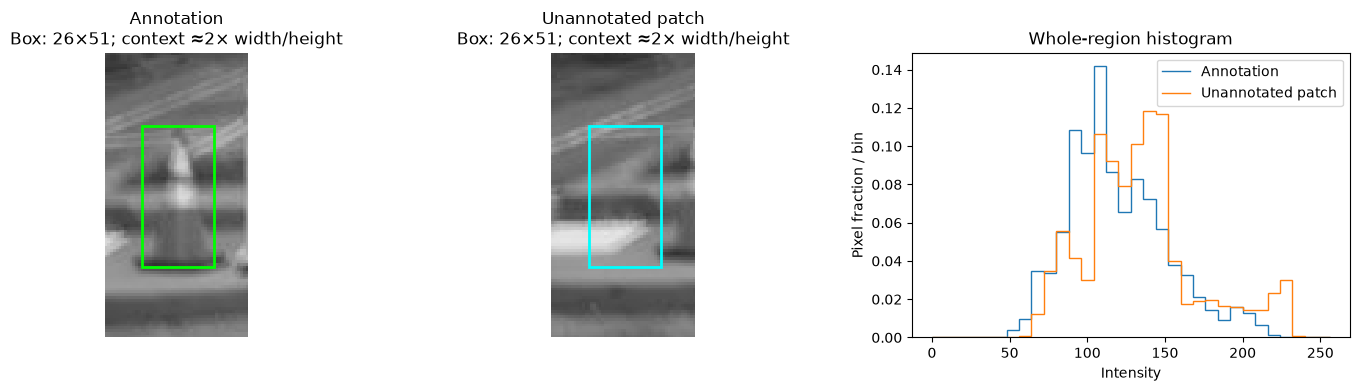

Example image: cone/306955271013985.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
0,cone_only,Histogram,40,78,0.51,0.2513


In [7]:
show_feature('cone_only', 'Histogram')

### Mean

Average brightness. Check whether differences persist across many images, not only this example.

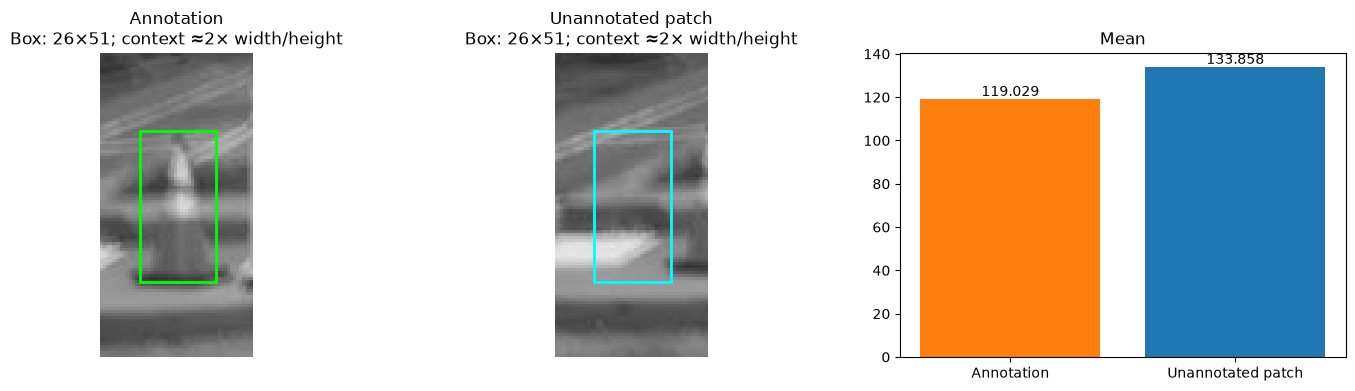

Example image: cone/306955271013985.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
1,cone_only,Mean,40,78,0.4475,0.1392


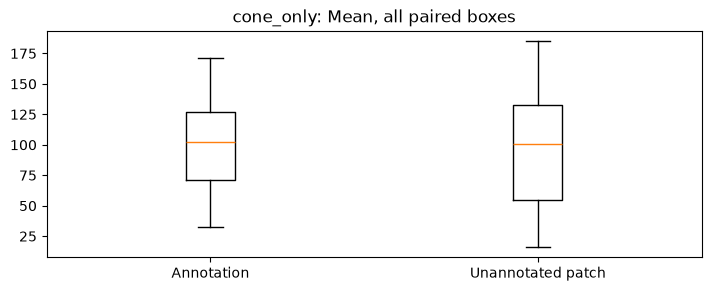

In [8]:
show_feature('cone_only', 'Mean')

### Variance

Population brightness variance. Large values indicate mixed bright/dark pixels, not necessarily a target.

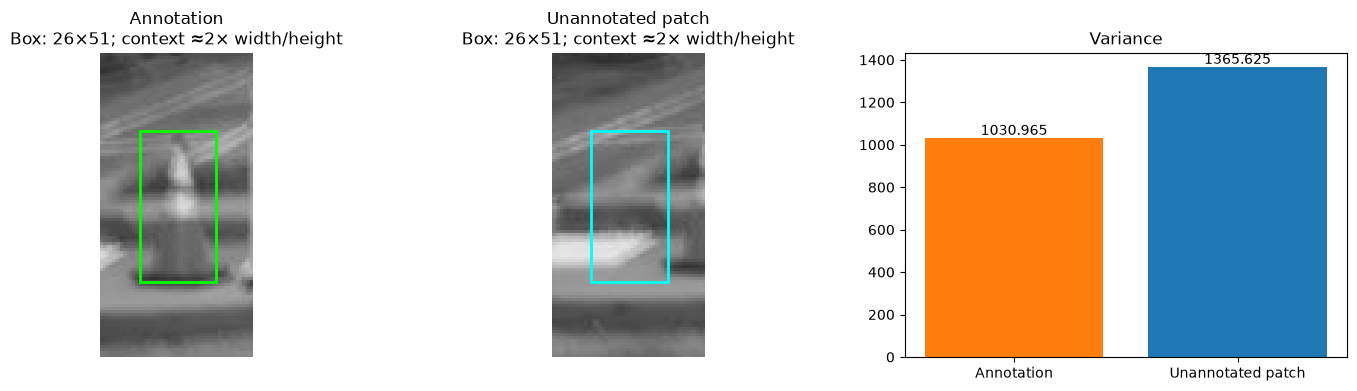

Example image: cone/306955271013985.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
2,cone_only,Variance,40,78,0.6042,0.2114


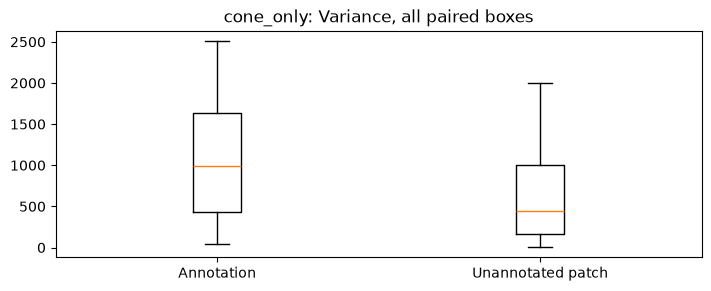

In [9]:
show_feature('cone_only', 'Variance')

### Std / RMS contrast

Square root of variance, in intensity units. Compare independently; its nearest-centroid decisions can differ after transformation.

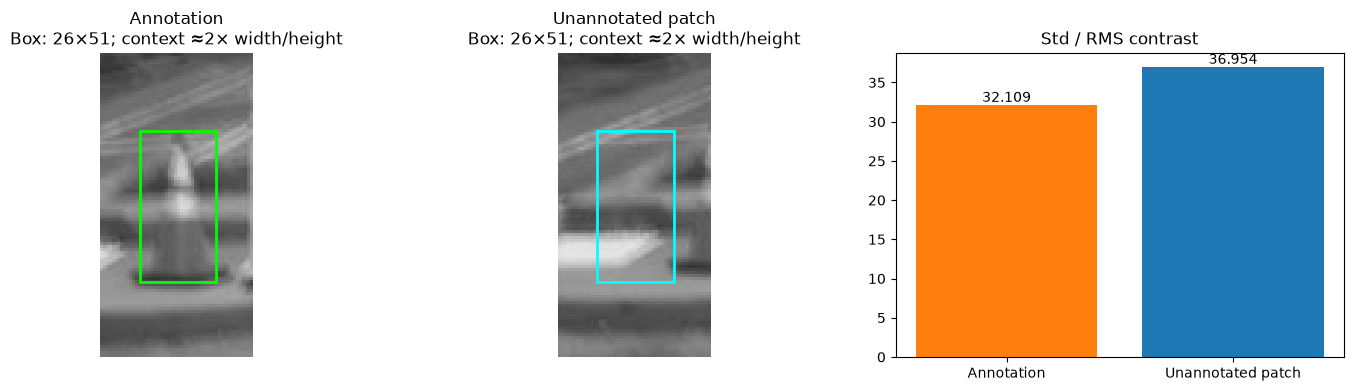

Example image: cone/306955271013985.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
3,cone_only,Std / RMS contrast,40,78,0.575,0.2326


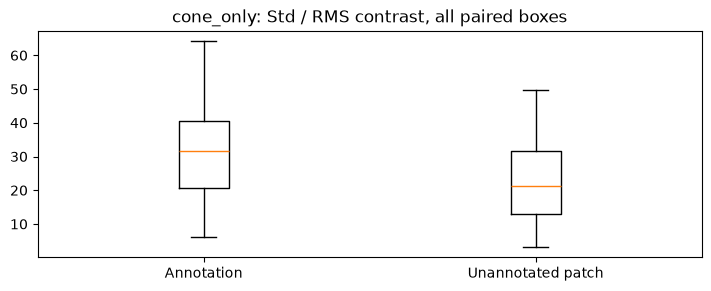

In [10]:
show_feature('cone_only', 'Std / RMS contrast')

### Median

Middle pixel brightness, less sensitive to extreme values.

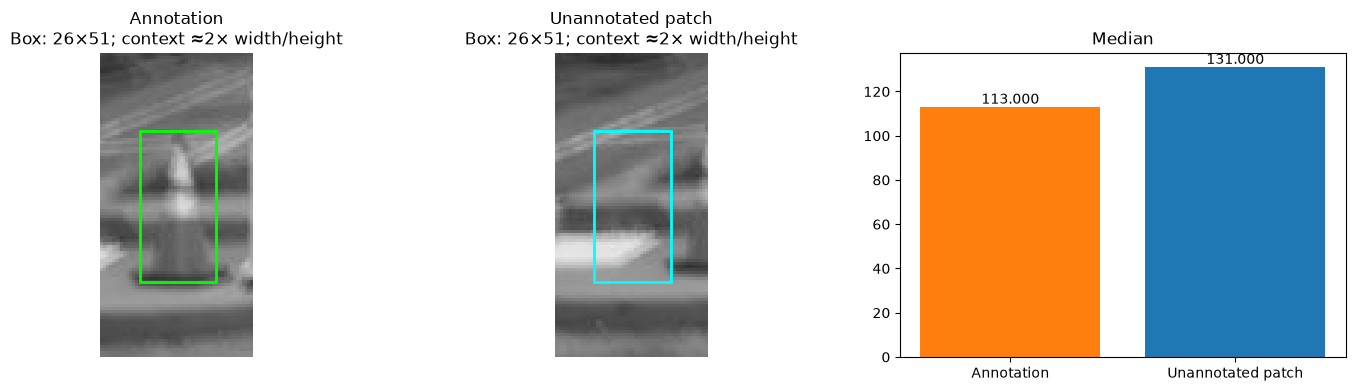

Example image: cone/306955271013985.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
4,cone_only,Median,40,78,0.4829,0.1027


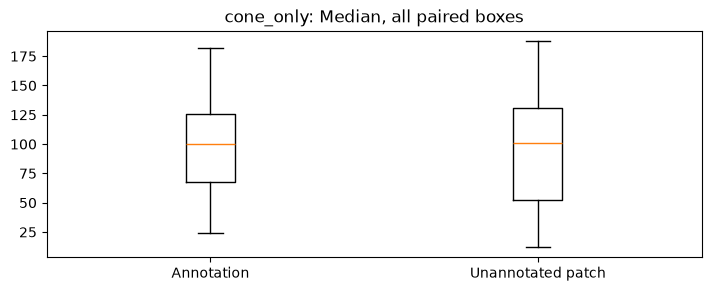

In [11]:
show_feature('cone_only', 'Median')

### Mode

Most frequent exact gray level. Ties choose the lowest level; small patches can make this unstable.

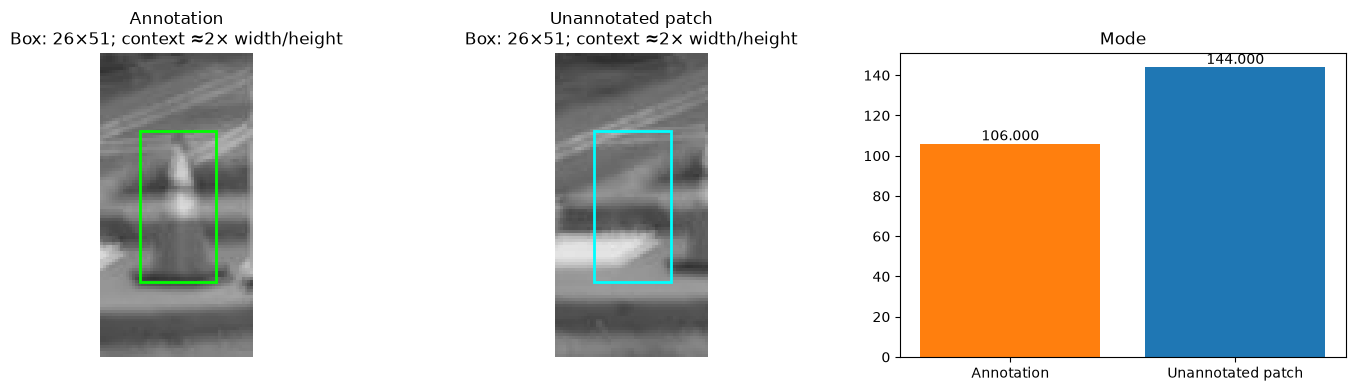

Example image: cone/306955271013985.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
5,cone_only,Mode,40,78,0.5367,0.1748


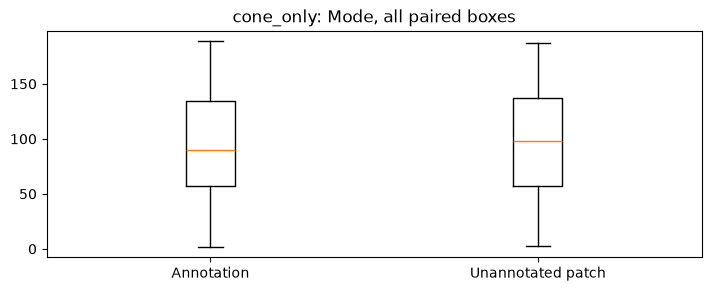

In [12]:
show_feature('cone_only', 'Mode')

### Trimmed mean

Average after removing 10% of pixels from each brightness tail.

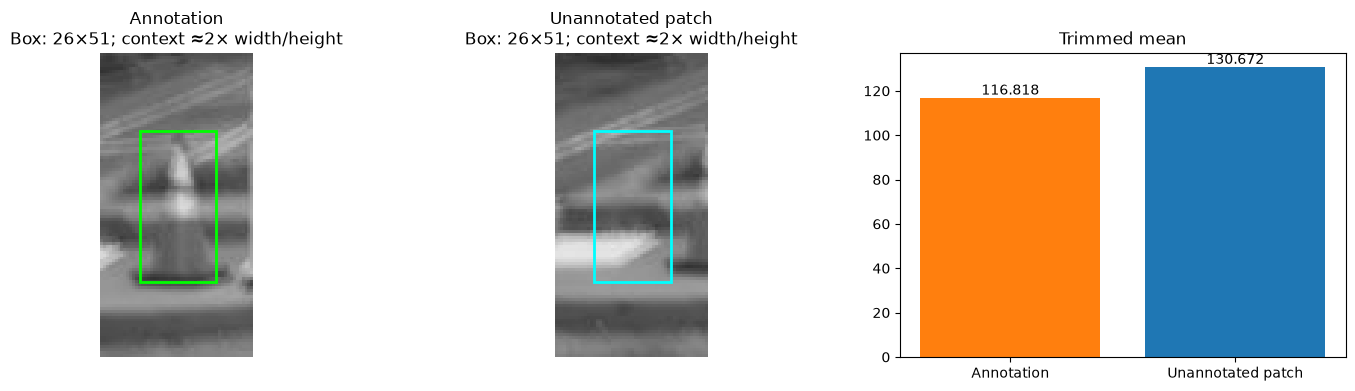

Example image: cone/306955271013985.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
6,cone_only,Trimmed mean,40,78,0.4475,0.1392


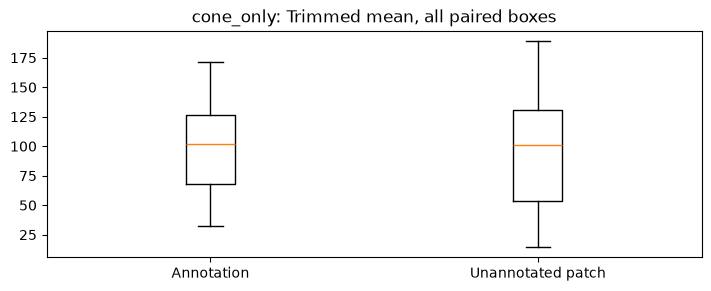

In [13]:
show_feature('cone_only', 'Trimmed mean')

### Entropy (bits)

Brightness diversity. A spatial shuffle leaves this value and the whole-region histogram unchanged.

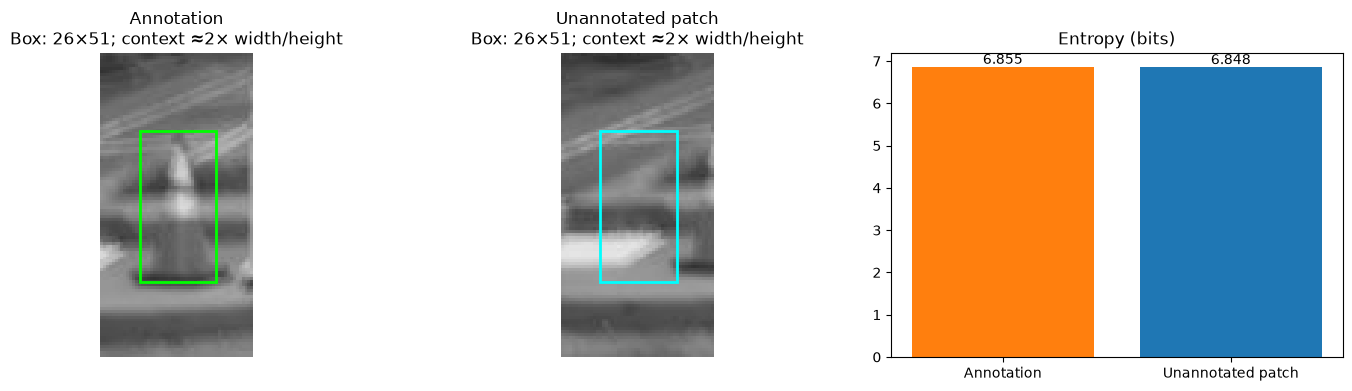

Example image: cone/306955271013985.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
7,cone_only,Entropy (bits),40,78,0.6419,0.2017


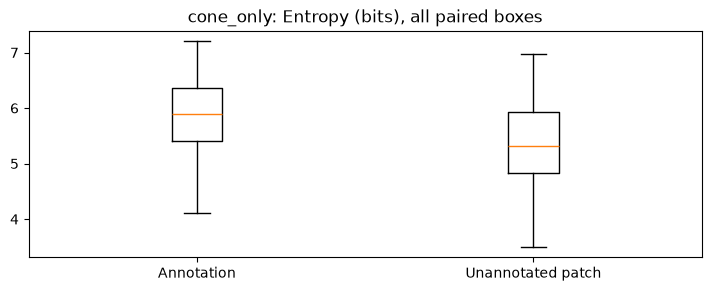

In [14]:
show_feature('cone_only', 'Entropy (bits)')

### Gray-range fraction

Fraction of pixels in [64,192]. This is one number per whole region, not the previous local heatmap.

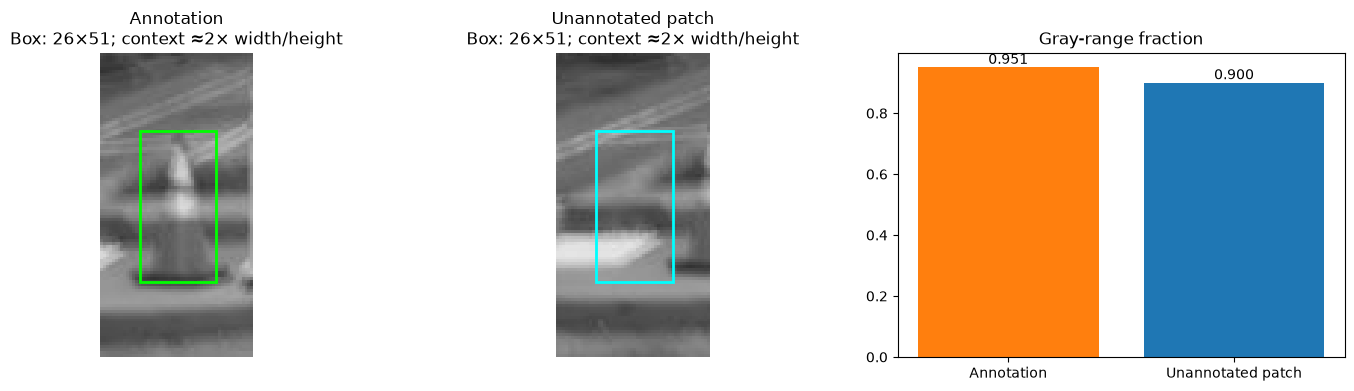

Example image: cone/306955271013985.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
8,cone_only,Gray-range fraction,40,78,0.4975,0.1545


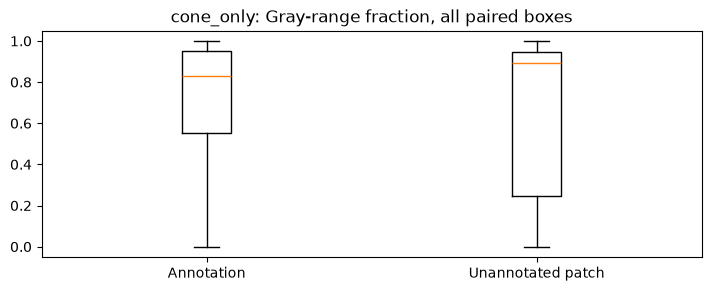

In [15]:
show_feature('cone_only', 'Gray-range fraction')

## sign_only — separate feature comparisons

Each cell shows a representative pair plus this group’s all-image comparison score.

### Histogram

Compare the full brightness distribution, preserving more information than a single average.

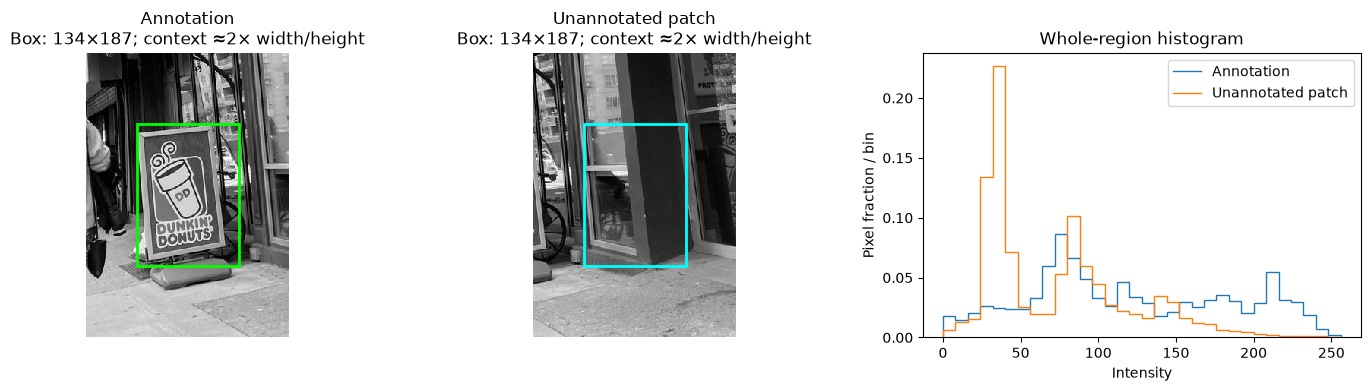

Example image: construction_sign/389248392311069.jpg ; object class: sign


,group,feature,images,pairs,balanced_accuracy,image_score_std
12,sign_only,Histogram,40,56,0.5875,0.277


In [16]:
show_feature('sign_only', 'Histogram')

### Mean

Average brightness. Check whether differences persist across many images, not only this example.

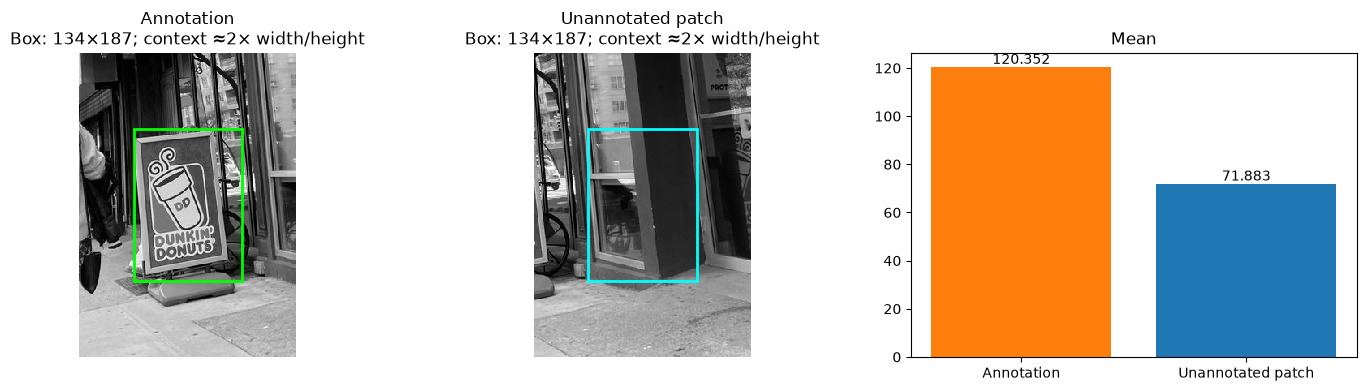

Example image: construction_sign/389248392311069.jpg ; object class: sign


,group,feature,images,pairs,balanced_accuracy,image_score_std
13,sign_only,Mean,40,56,0.5688,0.3149


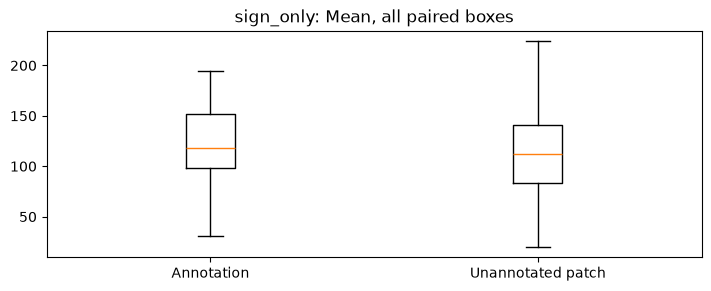

In [17]:
show_feature('sign_only', 'Mean')

### Variance

Population brightness variance. Large values indicate mixed bright/dark pixels, not necessarily a target.

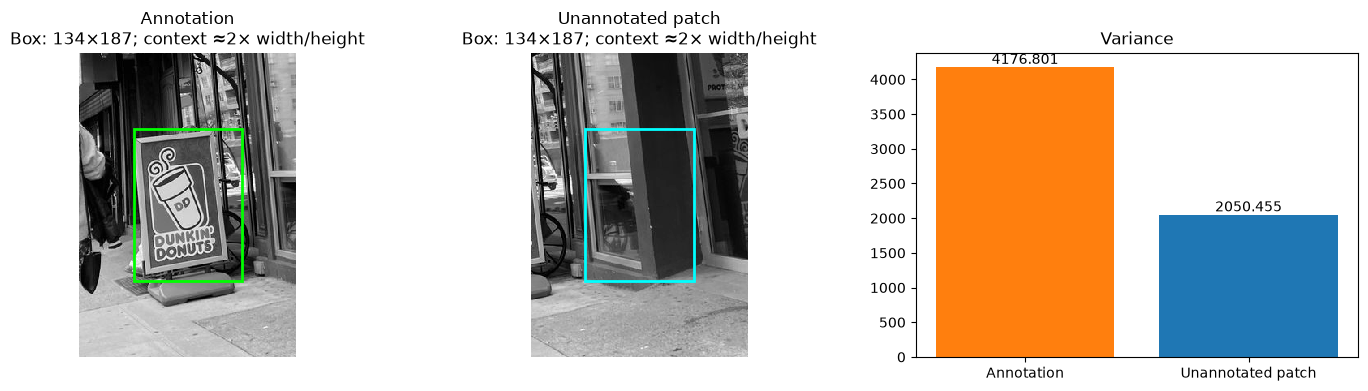

Example image: construction_sign/389248392311069.jpg ; object class: sign


,group,feature,images,pairs,balanced_accuracy,image_score_std
14,sign_only,Variance,40,56,0.5031,0.2802


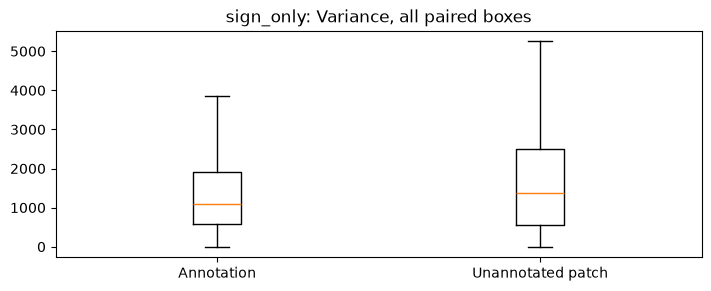

In [18]:
show_feature('sign_only', 'Variance')

### Std / RMS contrast

Square root of variance, in intensity units. Compare independently; its nearest-centroid decisions can differ after transformation.

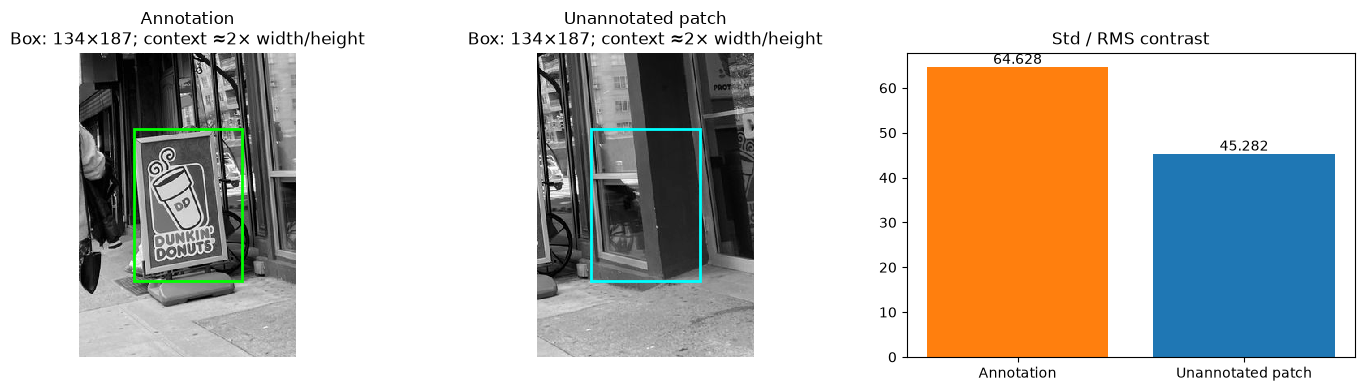

Example image: construction_sign/389248392311069.jpg ; object class: sign


,group,feature,images,pairs,balanced_accuracy,image_score_std
15,sign_only,Std / RMS contrast,40,56,0.4859,0.2679


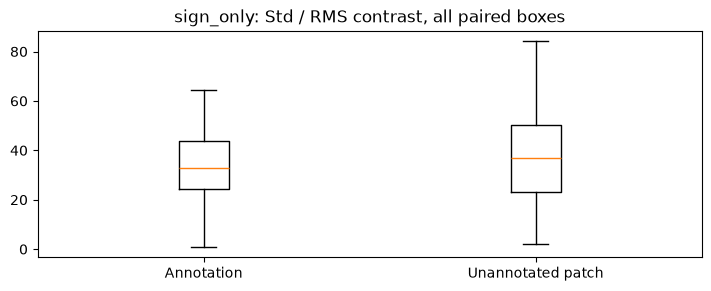

In [19]:
show_feature('sign_only', 'Std / RMS contrast')

### Median

Middle pixel brightness, less sensitive to extreme values.

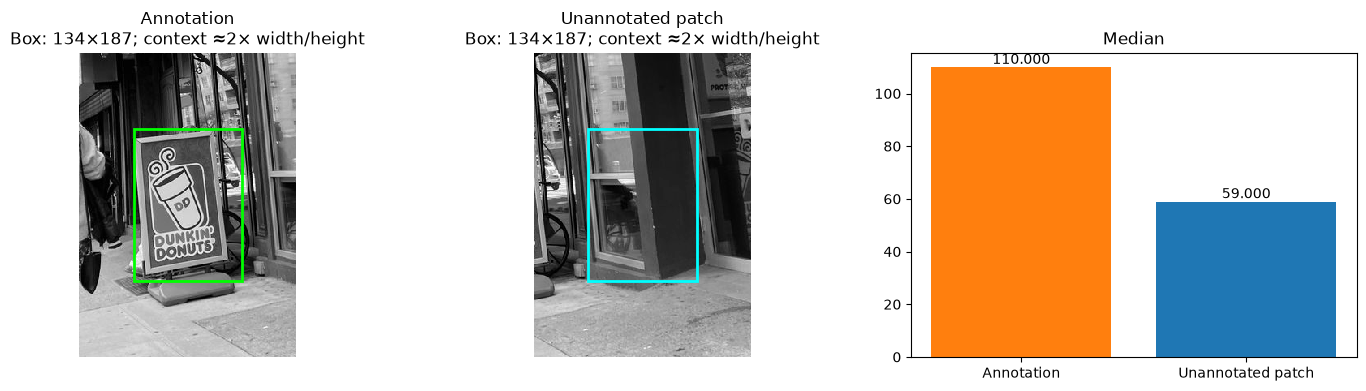

Example image: construction_sign/389248392311069.jpg ; object class: sign


,group,feature,images,pairs,balanced_accuracy,image_score_std
16,sign_only,Median,40,56,0.5734,0.2901


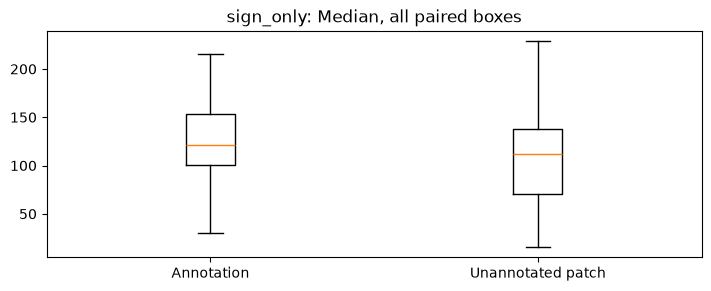

In [20]:
show_feature('sign_only', 'Median')

### Mode

Most frequent exact gray level. Ties choose the lowest level; small patches can make this unstable.

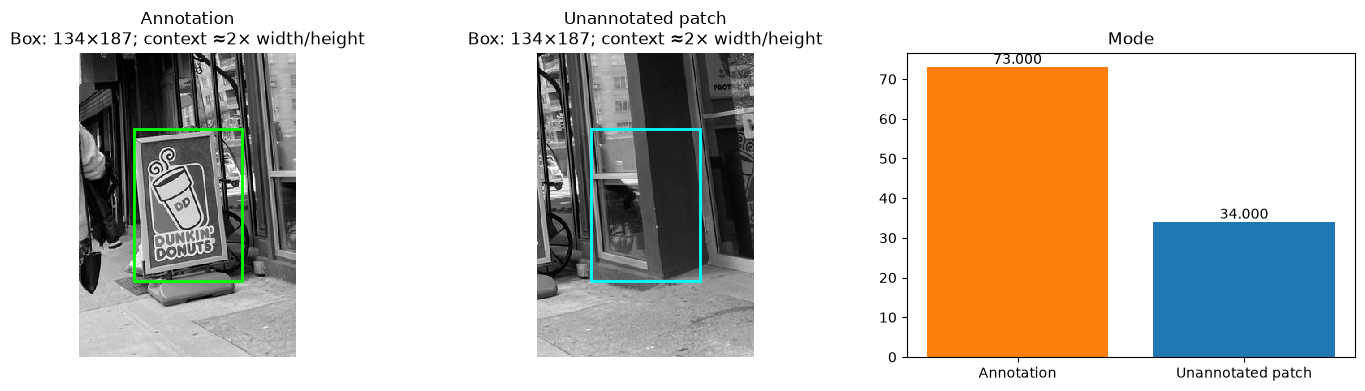

Example image: construction_sign/389248392311069.jpg ; object class: sign


,group,feature,images,pairs,balanced_accuracy,image_score_std
17,sign_only,Mode,40,56,0.6188,0.2666


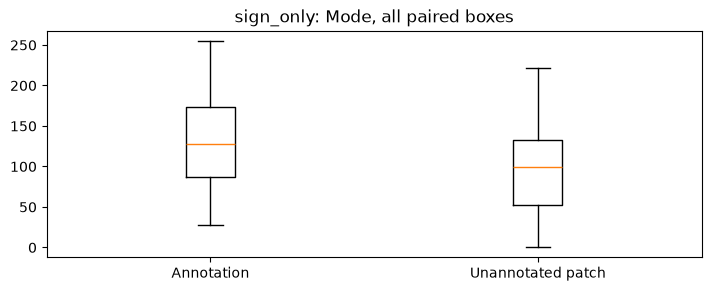

In [21]:
show_feature('sign_only', 'Mode')

### Trimmed mean

Average after removing 10% of pixels from each brightness tail.

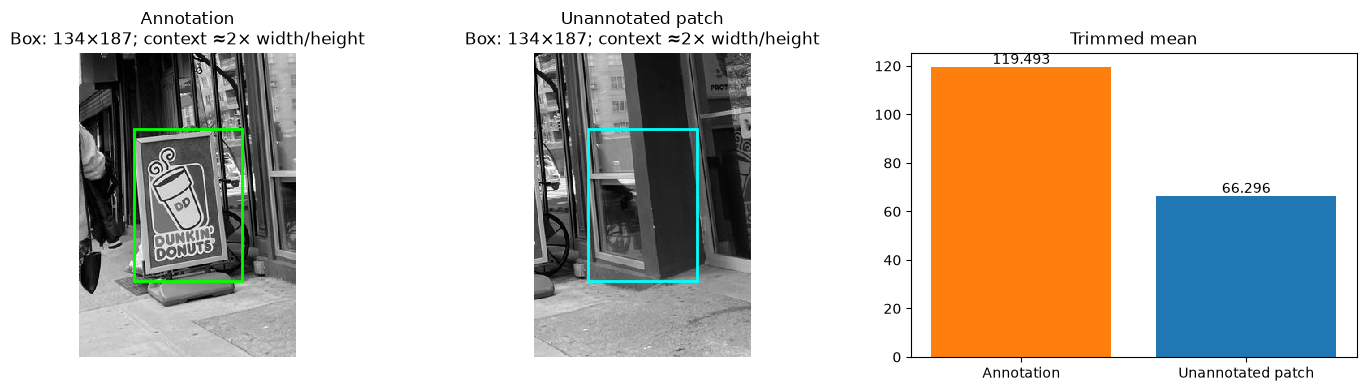

Example image: construction_sign/389248392311069.jpg ; object class: sign


,group,feature,images,pairs,balanced_accuracy,image_score_std
18,sign_only,Trimmed mean,40,56,0.5438,0.2992


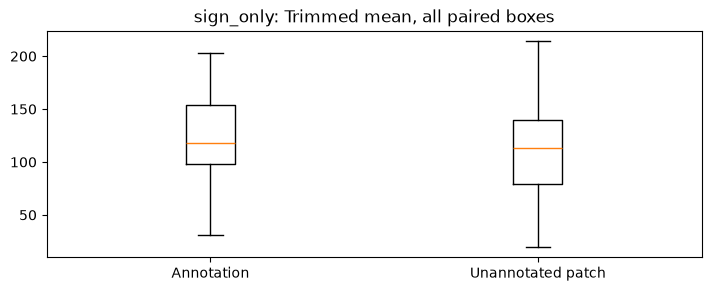

In [22]:
show_feature('sign_only', 'Trimmed mean')

### Entropy (bits)

Brightness diversity. A spatial shuffle leaves this value and the whole-region histogram unchanged.

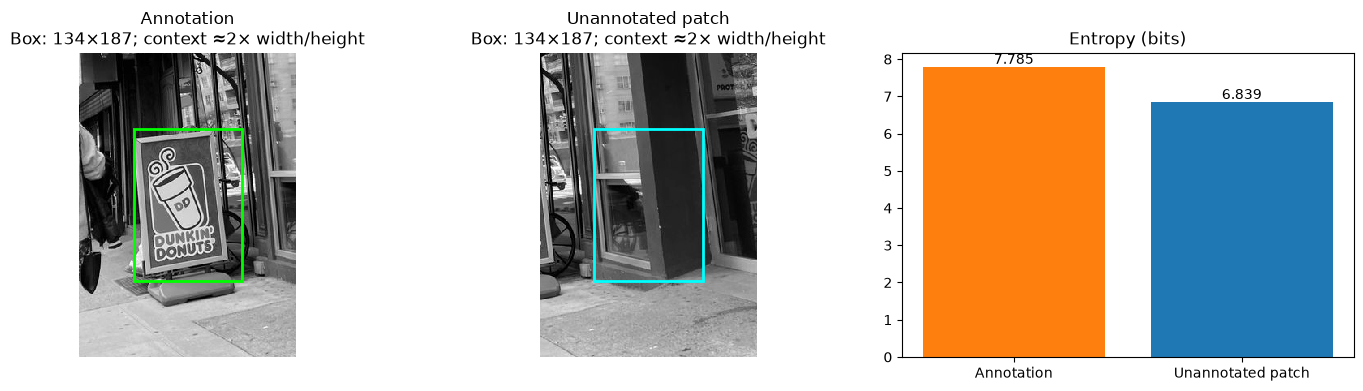

Example image: construction_sign/389248392311069.jpg ; object class: sign


,group,feature,images,pairs,balanced_accuracy,image_score_std
19,sign_only,Entropy (bits),40,56,0.5953,0.3223


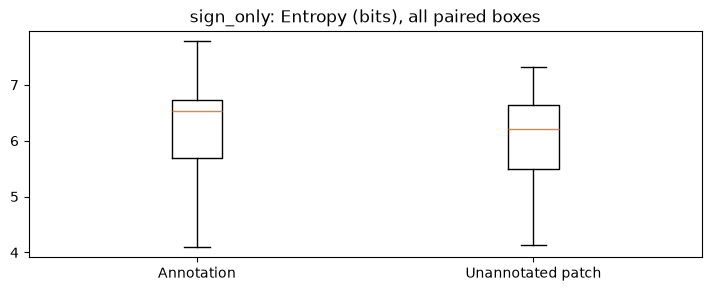

In [23]:
show_feature('sign_only', 'Entropy (bits)')

### Gray-range fraction

Fraction of pixels in [64,192]. This is one number per whole region, not the previous local heatmap.

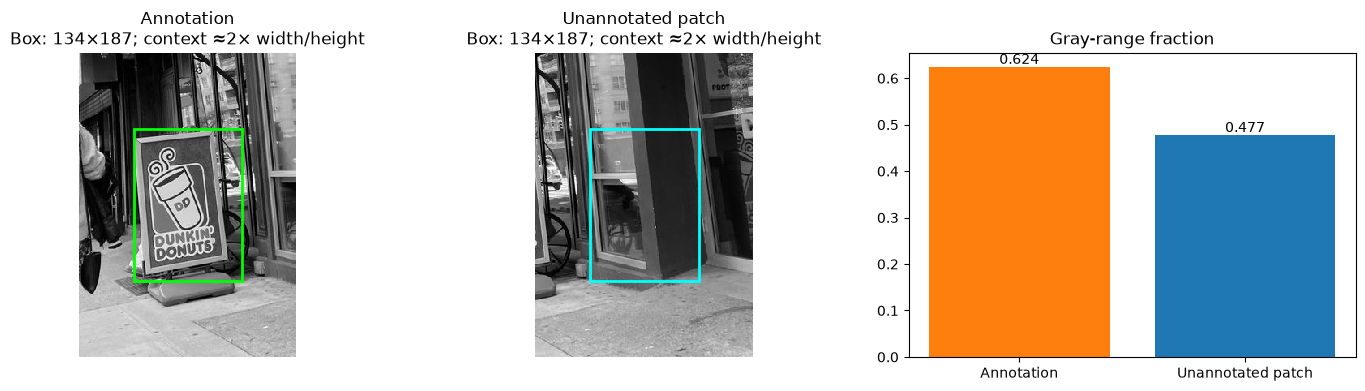

Example image: construction_sign/389248392311069.jpg ; object class: sign


,group,feature,images,pairs,balanced_accuracy,image_score_std
20,sign_only,Gray-range fraction,40,56,0.5109,0.2991


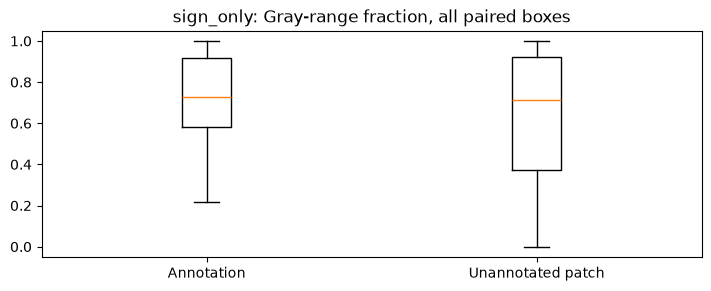

In [24]:
show_feature('sign_only', 'Gray-range fraction')

## both — separate feature comparisons

Each cell shows a representative pair plus this group’s all-image comparison score.

### Histogram

Compare the full brightness distribution, preserving more information than a single average.

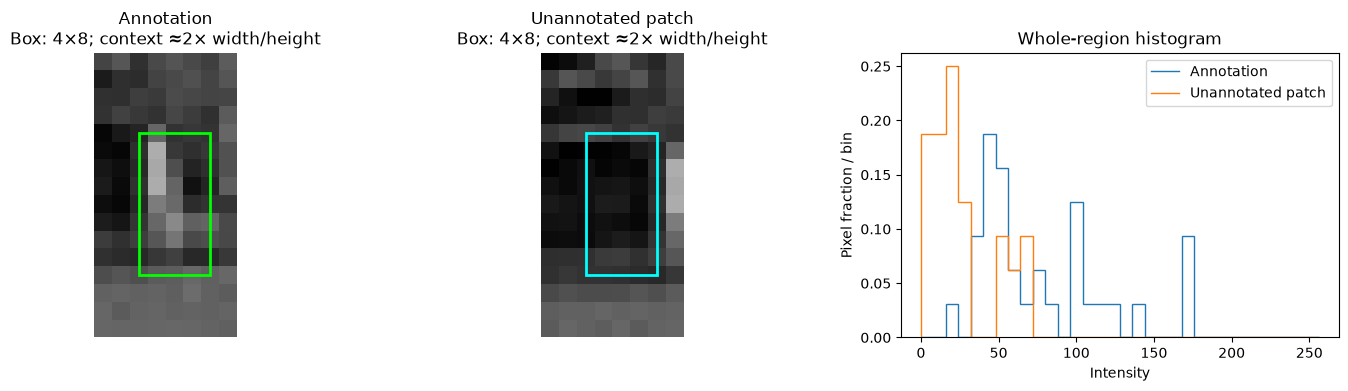

Example image: combination/8016379431742247.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
24,both,Histogram,16,94,0.5604,0.1846


In [25]:
show_feature('both', 'Histogram')

### Mean

Average brightness. Check whether differences persist across many images, not only this example.

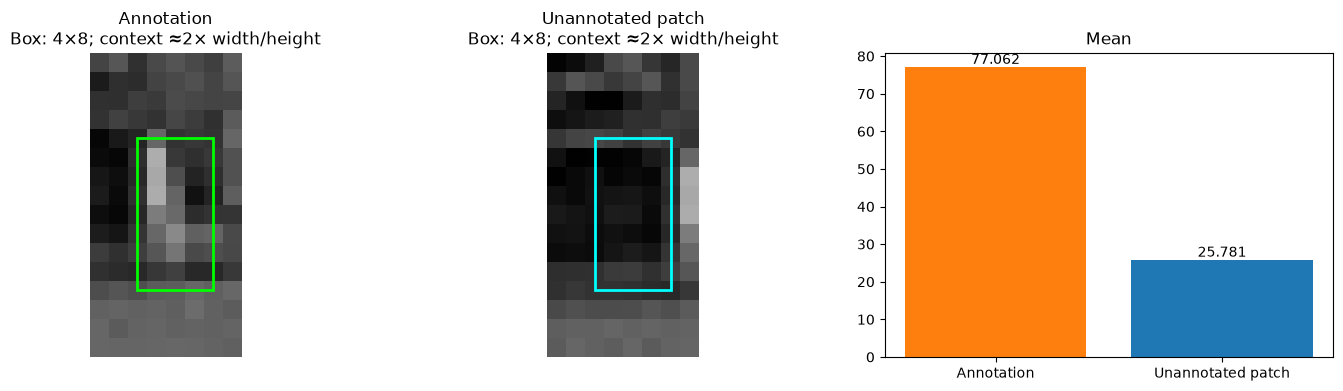

Example image: combination/8016379431742247.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
25,both,Mean,16,94,0.4854,0.0613


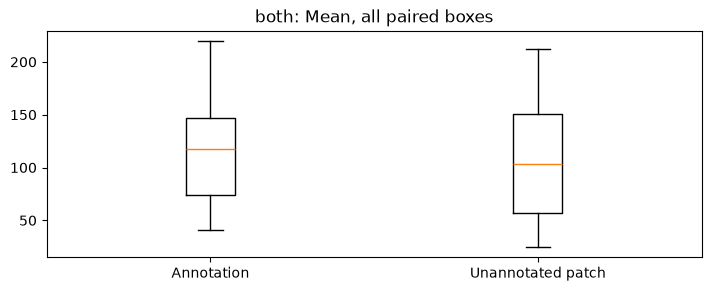

In [26]:
show_feature('both', 'Mean')

### Variance

Population brightness variance. Large values indicate mixed bright/dark pixels, not necessarily a target.

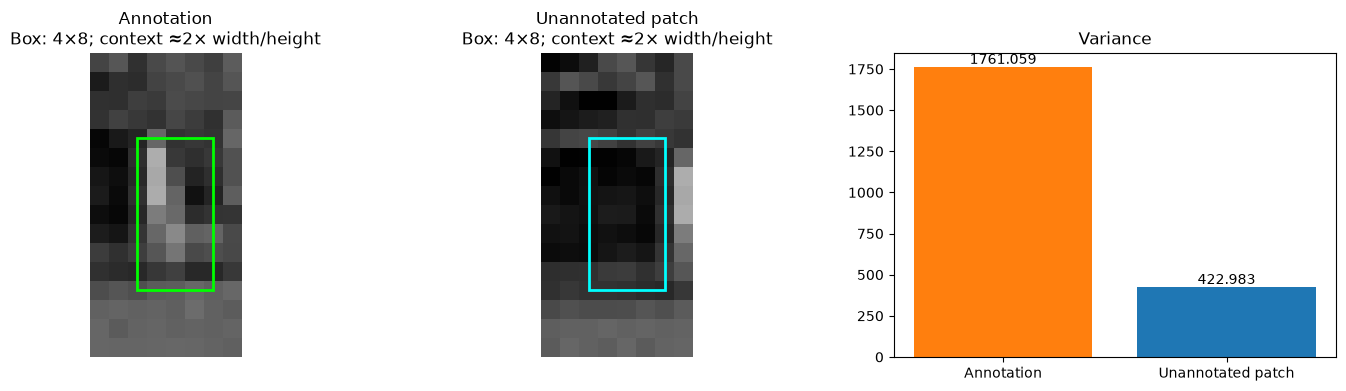

Example image: combination/8016379431742247.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
26,both,Variance,16,94,0.6293,0.1688


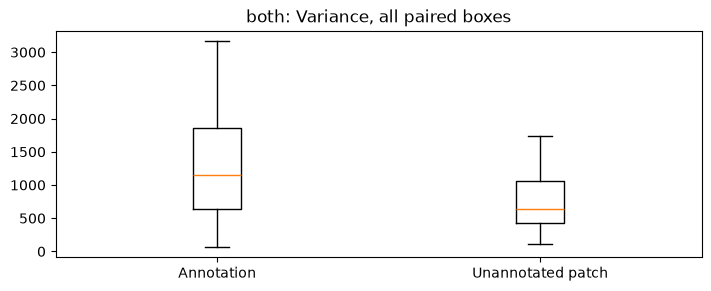

In [27]:
show_feature('both', 'Variance')

### Std / RMS contrast

Square root of variance, in intensity units. Compare independently; its nearest-centroid decisions can differ after transformation.

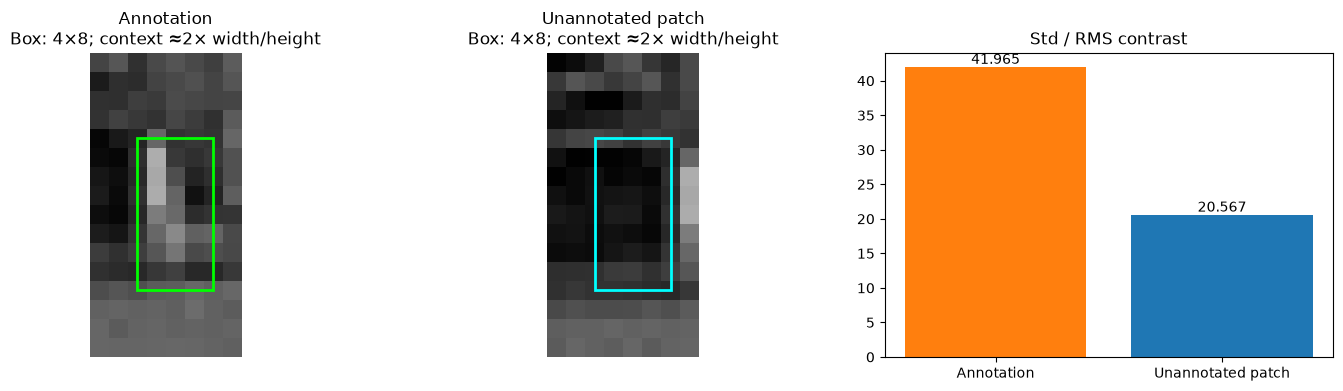

Example image: combination/8016379431742247.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
27,both,Std / RMS contrast,16,94,0.6705,0.1797


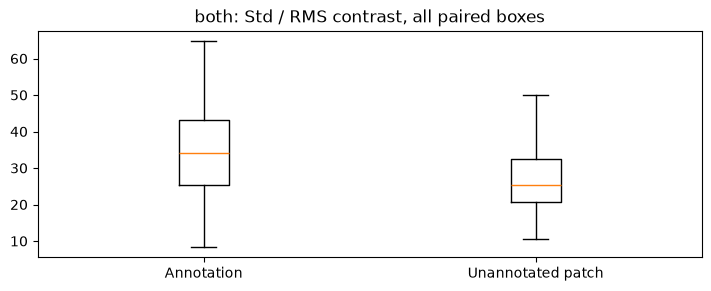

In [28]:
show_feature('both', 'Std / RMS contrast')

### Median

Middle pixel brightness, less sensitive to extreme values.

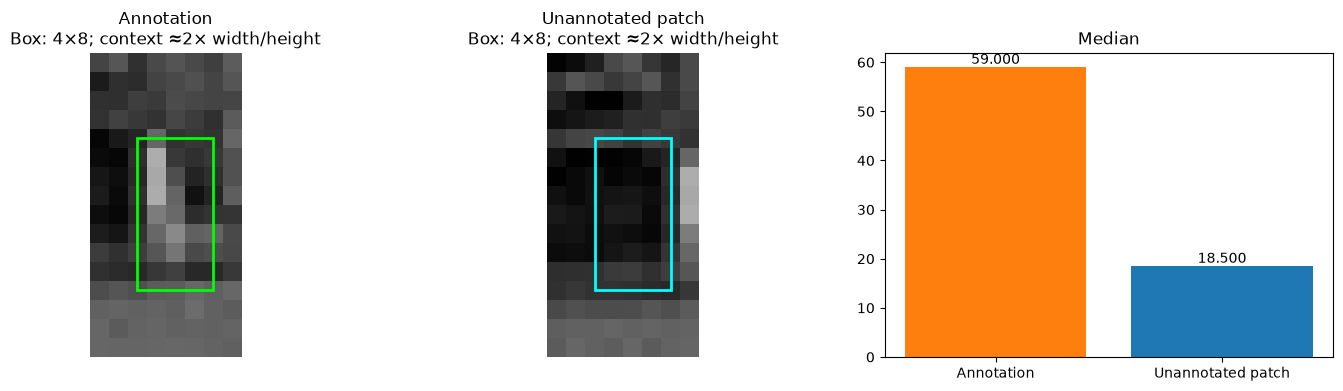

Example image: combination/8016379431742247.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
28,both,Median,16,94,0.4828,0.0682


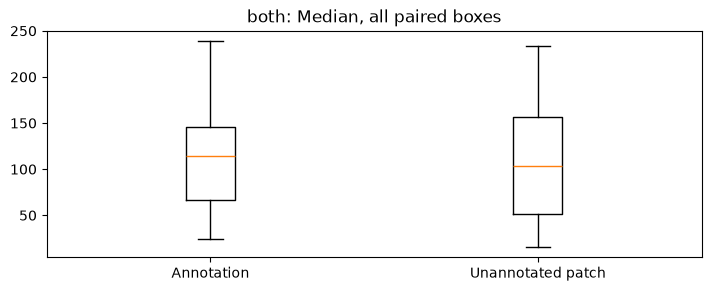

In [29]:
show_feature('both', 'Median')

### Mode

Most frequent exact gray level. Ties choose the lowest level; small patches can make this unstable.

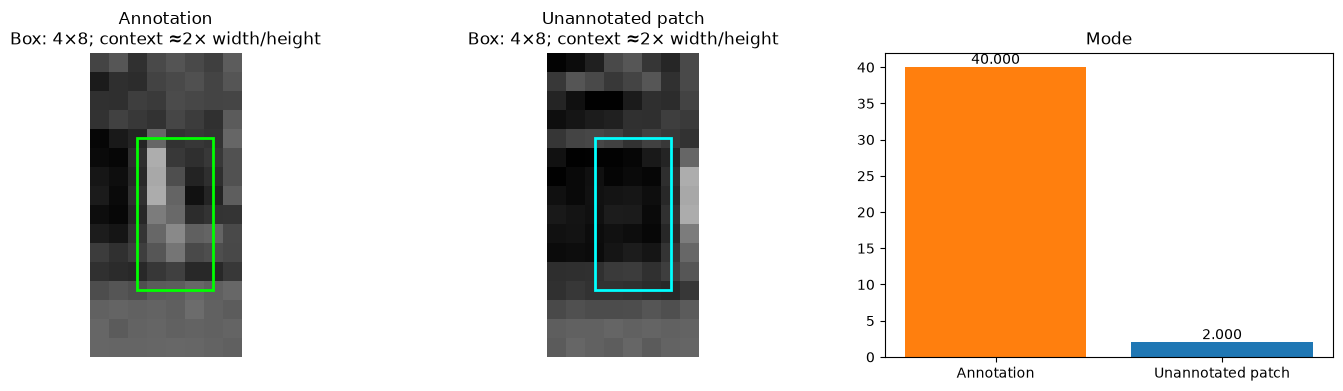

Example image: combination/8016379431742247.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
29,both,Mode,16,94,0.4727,0.1072


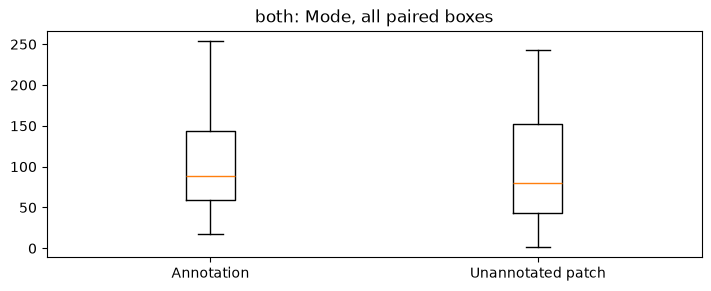

In [30]:
show_feature('both', 'Mode')

### Trimmed mean

Average after removing 10% of pixels from each brightness tail.

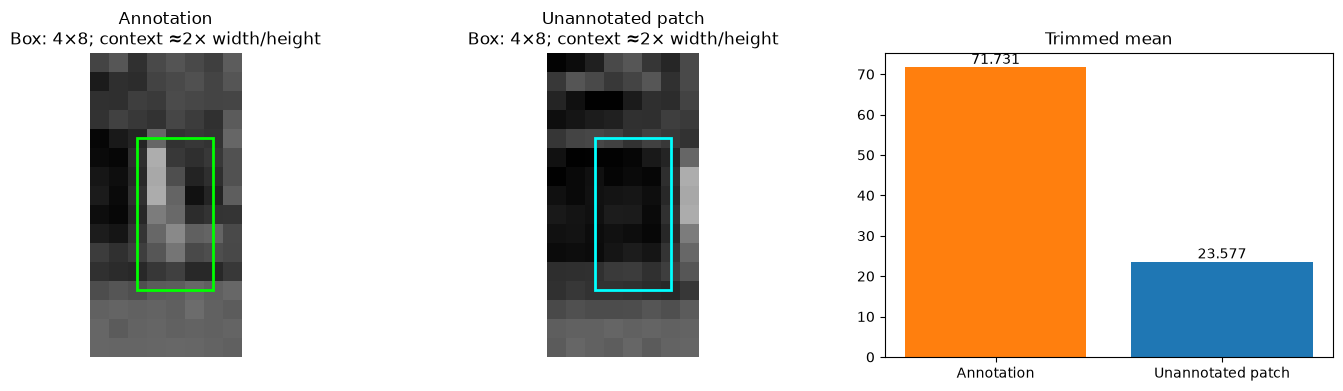

Example image: combination/8016379431742247.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
30,both,Trimmed mean,16,94,0.4874,0.0581


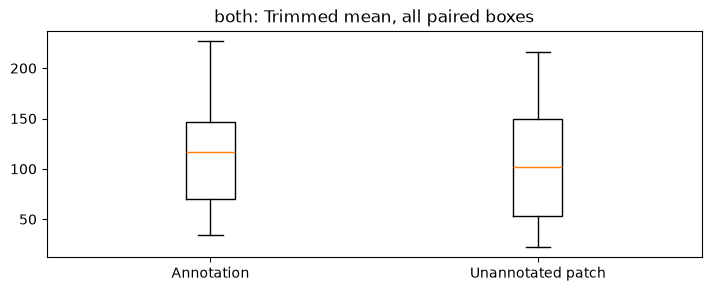

In [31]:
show_feature('both', 'Trimmed mean')

### Entropy (bits)

Brightness diversity. A spatial shuffle leaves this value and the whole-region histogram unchanged.

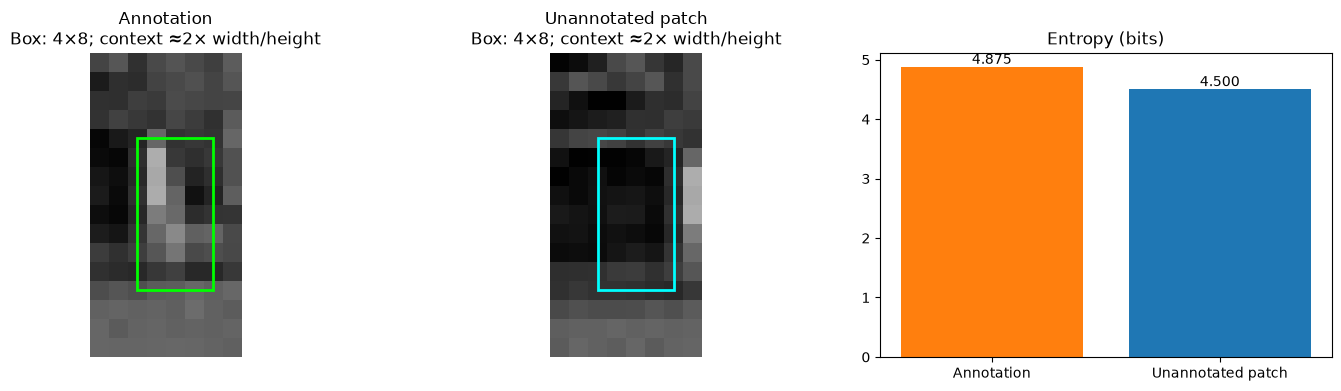

Example image: combination/8016379431742247.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
31,both,Entropy (bits),16,94,0.5682,0.1267


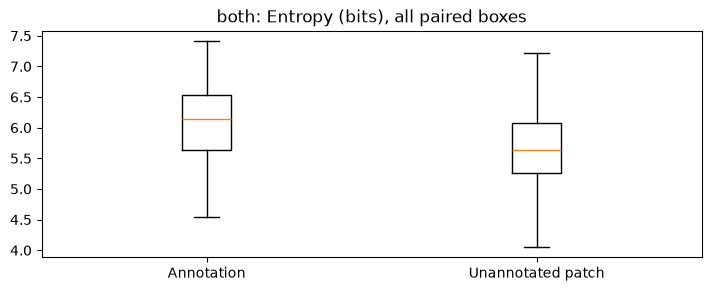

In [32]:
show_feature('both', 'Entropy (bits)')

### Gray-range fraction

Fraction of pixels in [64,192]. This is one number per whole region, not the previous local heatmap.

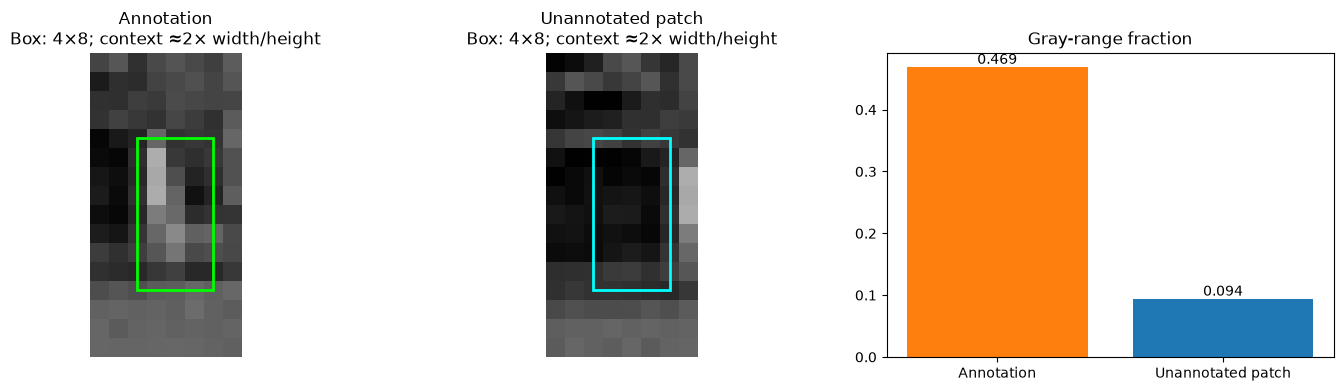

Example image: combination/8016379431742247.jpg ; object class: cone


,group,feature,images,pairs,balanced_accuracy,image_score_std
32,both,Gray-range fraction,16,94,0.4942,0.1625


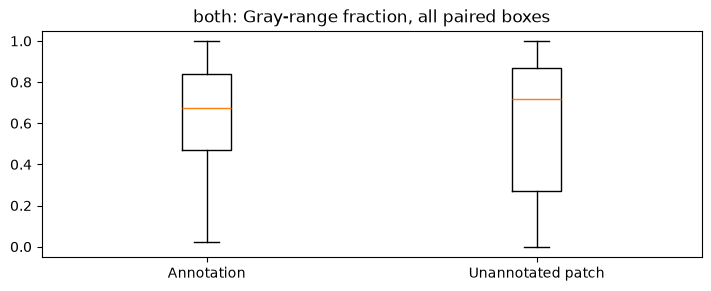

In [33]:
show_feature('both', 'Gray-range fraction')

## Summary and provisional choice

Sort separately within each group. A highest score is a **provisional reference under this comparison**, not a final detection choice. If the ordering changes by group, there is no universal winner from this experiment. Close differences require further evaluation rather than declaring a winner. Keep normalized Histogram as the baseline; evaluate promising alternatives on identical multi-scale windows before freezing the final pipeline.


In [34]:
for group in POSITIVE_GROUPS:
    table=comparison[comparison.group==group].sort_values('balanced_accuracy',ascending=False)
    print(group, '— whole-region feature comparison')
    display(table.round(4))
    best=table.iloc[0]
    print(f"Provisional reference: {best['feature']} ({best.balanced_accuracy:.1%}). Not final detector accuracy.")


cone_only — whole-region feature comparison


,group,feature,images,pairs,balanced_accuracy,image_score_std
7,cone_only,Entropy (bits),40,78,0.6419,0.2017
2,cone_only,Variance,40,78,0.6042,0.2114
11,cone_only,Mean + Std + Entropy,40,78,0.6031,0.1868
9,cone_only,Mean + Variance,40,78,0.5958,0.2169
10,cone_only,Variance + Entropy,40,78,0.5854,0.2412
3,cone_only,Std / RMS contrast,40,78,0.5750,0.2326
5,cone_only,Mode,40,78,0.5367,0.1748
0,cone_only,Histogram,40,78,0.5100,0.2513
8,cone_only,Gray-range fraction,40,78,0.4975,0.1545
4,cone_only,Median,40,78,0.4829,0.1027


Provisional reference: Entropy (bits) (64.2%). Not final detector accuracy.
sign_only — whole-region feature comparison


,group,feature,images,pairs,balanced_accuracy,image_score_std
17,sign_only,Mode,40,56,0.6188,0.2666
19,sign_only,Entropy (bits),40,56,0.5953,0.3223
22,sign_only,Variance + Entropy,40,56,0.5938,0.3233
12,sign_only,Histogram,40,56,0.5875,0.2770
16,sign_only,Median,40,56,0.5734,0.2901
13,sign_only,Mean,40,56,0.5688,0.3149
21,sign_only,Mean + Variance,40,56,0.5562,0.3271
18,sign_only,Trimmed mean,40,56,0.5438,0.2992
23,sign_only,Mean + Std + Entropy,40,56,0.5188,0.3018
20,sign_only,Gray-range fraction,40,56,0.5109,0.2991


Provisional reference: Mode (61.9%). Not final detector accuracy.
both — whole-region feature comparison


,group,feature,images,pairs,balanced_accuracy,image_score_std
27,both,Std / RMS contrast,16,94,0.6705,0.1797
26,both,Variance,16,94,0.6293,0.1688
33,both,Mean + Variance,16,94,0.6293,0.1688
34,both,Variance + Entropy,16,94,0.6070,0.1443
35,both,Mean + Std + Entropy,16,94,0.5954,0.1365
31,both,Entropy (bits),16,94,0.5682,0.1267
24,both,Histogram,16,94,0.5604,0.1846
32,both,Gray-range fraction,16,94,0.4942,0.1625
30,both,Trimmed mean,16,94,0.4874,0.0581
25,both,Mean,16,94,0.4854,0.0613


Provisional reference: Std / RMS contrast (67.0%). Not final detector accuracy.


## Optional interactive check — whole-region features only

Choose a group, image, annotation and feature. No internal neighborhood size or local heatmap is used. Unannotated areas may still contain missed targets.


In [35]:
import ipywidgets as widgets
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

group_picker=widgets.Dropdown(options=POSITIVE_GROUPS,description='Group')
image_picker=widgets.Dropdown(description='Image',layout=widgets.Layout(width='600px'))
box_picker=widgets.Dropdown(description='Box')
feature_picker=widgets.Dropdown(options=FEATURES,description='Feature')
out=widgets.Output()
changing=False

def update_plot(*_):
    if changing or box_picker.value is None:return
    with out:
        out.clear_output(wait=True)
        rgb,gray,row,regions,boxes=region_data(image_picker.value,box_picker.value)
        display(region_table(regions).round(3))
        fig,axes=plt.subplots(1,3,figsize=(15,4),layout='constrained')
        show_context(axes[0],gray,boxes['Annotation'],'Annotation')
        if 'Unannotated patch' in boxes:
            show_context(axes[1],gray,boxes['Unannotated patch'],'Unannotated patch',color='cyan')
        else:
            axes[1].axis('off')
        chart=axes[2]
        f=feature_picker.value
        if f=='Histogram':
            for name,patch in regions.items():
                h,e=intensity_histogram(patch,BINS);chart.stairs(h,e,label=name)
            chart.legend();chart.set(xlabel='Intensity',ylabel='Pixel fraction / bin')
        else:
            chart.bar(range(len(regions)),[intensity_statistics(p)[f] for p in regions.values()])
            chart.set_xticks(range(len(regions)),list(regions),rotation=30,ha='right')
        chart.set_title(f);plt.show()

def update_boxes(*_):
    global changing
    changing=True
    rows=objects[objects.image==image_picker.value].reset_index(drop=True)
    box_picker.options=[(f"{i}: {r['class']}",i) for i,r in rows.iterrows()]
    changing=False;update_plot()

def update_images(*_):
    global changing
    changing=True
    image_picker.options=[n for n in images[images.group==group_picker.value].image if n in set(objects.image)]
    changing=False;update_boxes()

group_picker.observe(update_images,names='value')
image_picker.observe(update_boxes,names='value')
box_picker.observe(update_plot,names='value')
feature_picker.observe(update_plot,names='value')
display(widgets.VBox([group_picker,image_picker,box_picker,feature_picker,out]))
update_images()
